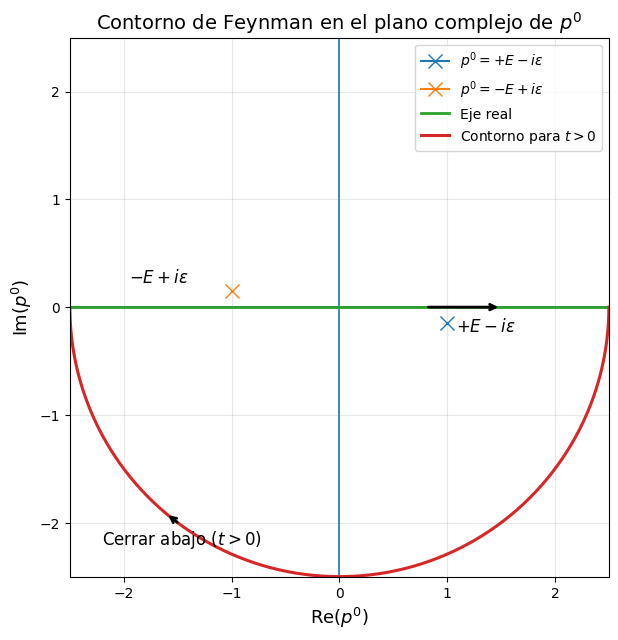

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

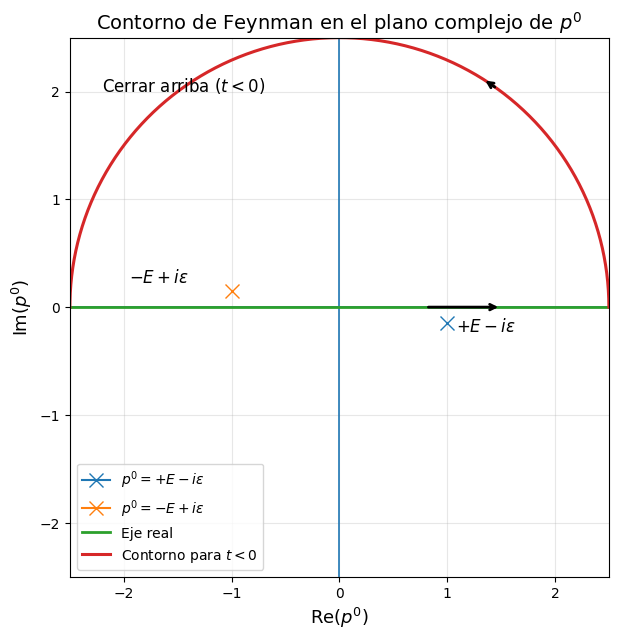

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

def graficar_contorno(t_sign=1, E=1.0, eps=0.15, radio=2.5, label=""):
    """
    t_sign = +1  -> caso t > 0, se cierra abajo
    t_sign = -1  -> caso t < 0, se cierra arriba
    """

    fig, ax = plt.subplots(figsize=(7, 7))
    ax.set_aspect('equal', 'box')
    ax.set_xlim(-radio, radio)
    ax.set_ylim(-radio, radio)

    # Ejes
    ax.axhline(0, linewidth=1.2)
    ax.axvline(0, linewidth=1.2)

    # Polos
    polo_inferior = (E, -eps)
    polo_superior = (-E, eps)

    ax.plot(*polo_inferior, marker='x', markersize=10, label=r"$p^0=+E-i\epsilon$")
    ax.plot(*polo_superior, marker='x', markersize=10, label=r"$p^0=-E+i\epsilon$")

    ax.text(E + 0.08, -eps - 0.08, r"$+E-i\epsilon$", fontsize=12)
    ax.text(-E - 0.95, eps + 0.08, r"$-E+i\epsilon$", fontsize=12)

    # Camino sobre el eje real
    x = np.linspace(-radio, radio, 400)
    y = np.zeros_like(x)
    ax.plot(x, y, linewidth=2, label="Eje real")

    # Flecha sobre el eje real
    ax.annotate(
        "",
        xy=(1.5, 0),
        xytext=(0.8, 0),
        arrowprops=dict(arrowstyle="->", lw=2)
    )

    # Contorno semicircular
    theta = np.linspace(0, np.pi, 300)

    if t_sign > 0:
        # Cierre hacia abajo
        x_cont = radio * np.cos(theta)
        y_cont = -radio * np.sin(theta)
        ax.plot(x_cont, y_cont, linewidth=2.2, label=r"Contorno para $t>0$")
        ax.text(-2.2, -2.2, r"Cerrar abajo ($t>0$)", fontsize=12)

        # Flecha en el arco
        i = 210
        ax.annotate(
            "",
            xy=(x_cont[i+6], y_cont[i+6]),
            xytext=(x_cont[i], y_cont[i]),
            arrowprops=dict(arrowstyle="->", lw=2)
        )

    else:
        # Cierre hacia arriba
        x_cont = radio * np.cos(theta)
        y_cont = radio * np.sin(theta)
        ax.plot(x_cont, y_cont, linewidth=2.2, label=r"Contorno para $t<0$")
        ax.text(-2.2, 2.0, r"Cerrar arriba ($t<0$)", fontsize=12)

        # Flecha en el arco
        i = 90
        ax.annotate(
            "",
            xy=(x_cont[i+6], y_cont[i+6]),
            xytext=(x_cont[i], y_cont[i]),
            arrowprops=dict(arrowstyle="->", lw=2)
        )

    ax.set_xlabel(r"$\mathrm{Re}(p^0)$", fontsize=13)
    ax.set_ylabel(r"$\mathrm{Im}(p^0)$", fontsize=13)
    ax.set_title("Contorno de Feynman en el plano complejo de $p^0$", fontsize=14)
    ax.grid(True, alpha=0.3)
    ax.legend()
    plt.savefig("contorno_feynman_"+label+".pdf", dpi=300)
    plt.show()
    files.download("contorno_feynman_"+label+".pdf")


# Caso 1: t > 0, se cierra abajo
graficar_contorno(t_sign=1, E=1.0, eps=0.15, radio=2.5,label="Positivo")

# Caso 2: t < 0, se cierra arriba
graficar_contorno(t_sign=-1, E=1.0, eps=0.15, radio=2.5,label="Negativo")